In [1]:
!pip install wfdb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 2.3 MB/s eta 0:00:00


In [2]:
import wfdb
import pandas as pd
from google.colab import files

# Set the record name
record_name = '100'

# Read the record (dat) and annotation (atr) files
record = wfdb.rdrecord(record_name)
annotation = wfdb.rdann(record_name, 'atr')

# Create a DataFrame with the signal data
df_signals = pd.DataFrame(record.p_signal, columns=[f'Signal_{i}' for i in range(record.p_signal.shape[1])])
df_signals['Time'] = [x / record.fs for x in range(record.p_signal.shape[0])]

# Create a DataFrame with the annotations
df_annotations = pd.DataFrame({
    'Sample': annotation.sample,
    'Annotation': annotation.symbol
})

# Merge signal and annotation data
df = df_signals.merge(df_annotations, how='left', left_index=True, right_on='Sample')

# Save to CSV
csv_file = 'ecg_data_100.csv'
df.to_csv(csv_file, index=False)

# Download the CSV file
files.download(csv_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import pandas as pd

# Load the ECG data
df = pd.read_csv('ecg_data_100.csv')


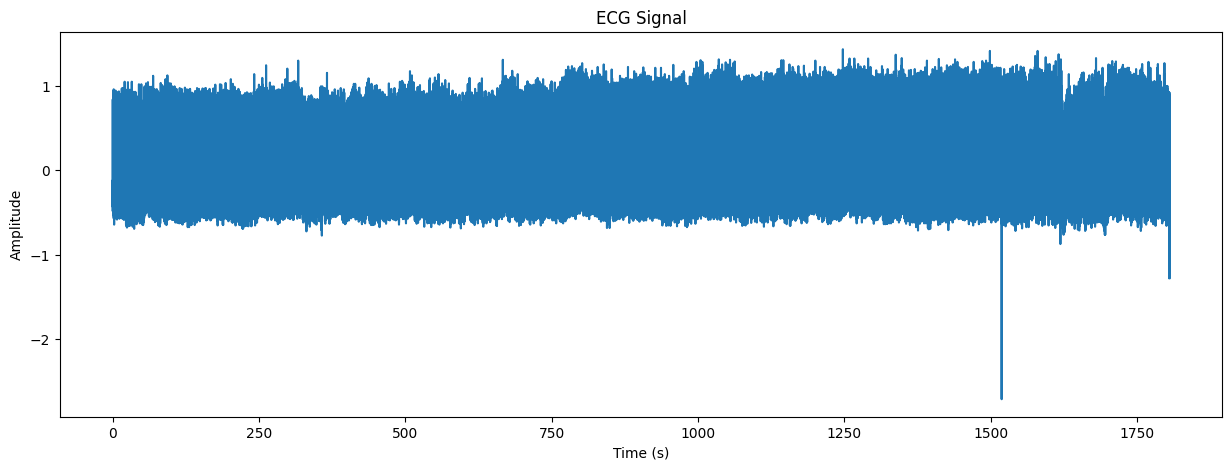

In [4]:
import matplotlib.pyplot as plt

# Plot the ECG signal
plt.figure(figsize=(15, 5))
plt.plot(df['Time'], df['Signal_0'])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('ECG Signal')
plt.show()


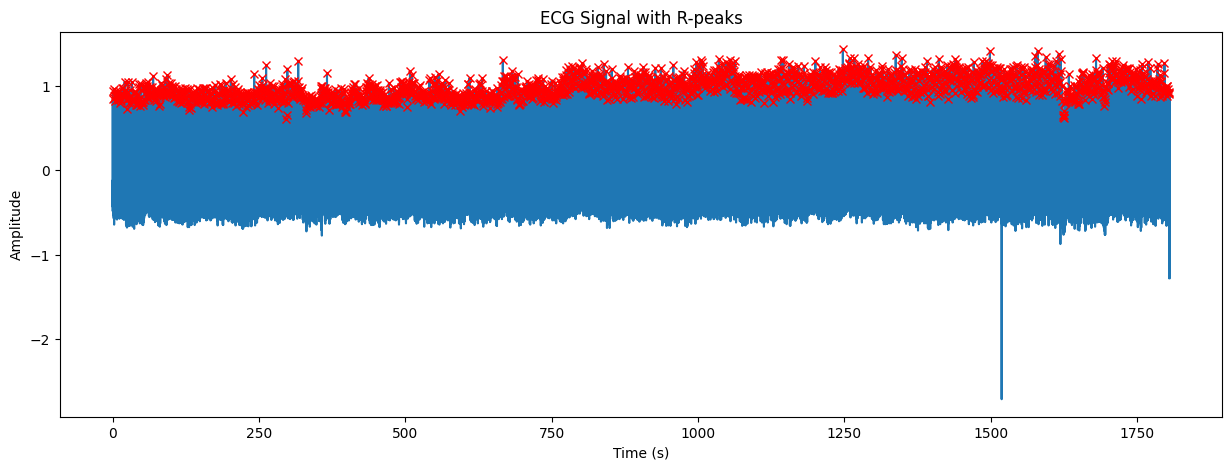

In [5]:
import numpy as np
from scipy.signal import find_peaks

# Detect R-peaks (simple example, for demonstration purposes)
signal = df['Signal_0'].values
peaks, _ = find_peaks(signal, height=0.5)  # Adjust height threshold as needed

# Calculate R-R intervals
rr_intervals = np.diff(peaks) / record.fs  # Convert to seconds

# Plot detected R-peaks on the ECG signal
plt.figure(figsize=(15, 5))
plt.plot(df['Time'], signal)
plt.plot(df['Time'][peaks], signal[peaks], 'rx')  # Mark R-peaks with red x
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('ECG Signal with R-peaks')
plt.show()


In [8]:
# Display unique annotations
print(df['Annotation'].unique())


[nan '+' 'N' 'A' 'V']


In [11]:
# Filter for PVC annotations
pvc_df = df[df['Annotation'] == 'A']

# Display the PVC events
print(pvc_df)


        Signal_0  Signal_1         Time  Sample Annotation
2044       0.845     0.500     5.677778    2044          A
66792      1.015     0.005   185.533333   66792          A
74986      0.990     0.360   208.294444   74986          A
99579      0.830     0.235   276.608333   99579          A
128085     0.950     0.325   355.791667  128085          A
170719     0.840     0.130   474.219444  170719          A
279576     0.905     0.045   776.600000  279576          A
305709     0.990     0.135   849.191667  305709          A
307745     0.975     0.125   854.847222  307745          A
312825     0.890     0.445   868.958333  312825          A
317785     0.865     0.080   882.736111  317785          A
319223     0.985     0.070   886.730556  319223          A
346804     0.790    -0.075   963.344444  346804          A
351481     1.135     0.375   976.336111  351481          A
377081     1.270     0.545  1047.447222  377081          A
397335     0.780     0.320  1103.708333  397335         

Unique annotations: ['+' 'N' 'A' 'V']


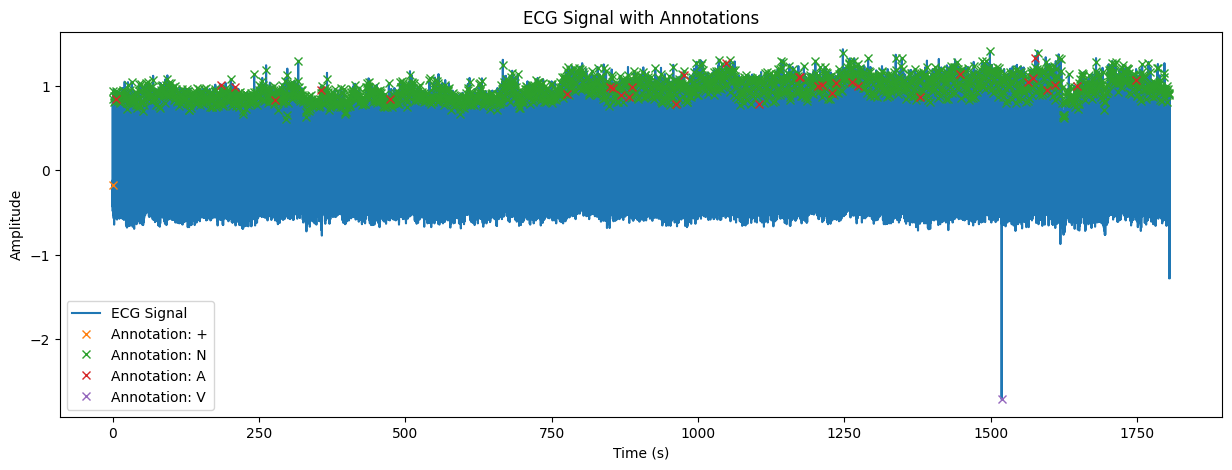

Arrhythmia detected based on annotations.


In [13]:
import wfdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the record and annotation
record_name = '100'
record = wfdb.rdrecord(record_name)
annotation = wfdb.rdann(record_name, 'atr')

# Create a DataFrame with the signal data
df_signals = pd.DataFrame(record.p_signal, columns=[f'Signal_{i}' for i in range(record.p_signal.shape[1])])
df_signals['Time'] = [x / record.fs for x in range(record.p_signal.shape[0])]

# Create a DataFrame with the annotations
df_annotations = pd.DataFrame({
    'Sample': annotation.sample,
    'Time': annotation.sample / record.fs,
    'Annotation': annotation.symbol
})

# Display unique annotations
unique_annotations = df_annotations['Annotation'].unique()
print(f"Unique annotations: {unique_annotations}")

# Plot the ECG signal with annotations
plt.figure(figsize=(15, 5))
plt.plot(df_signals['Time'], df_signals['Signal_0'], label='ECG Signal')

# Mark annotations on the plot
for annotation in unique_annotations:
    annotation_samples = df_annotations[df_annotations['Annotation'] == annotation]['Sample']
    annotation_times = df_annotations[df_annotations['Annotation'] == annotation]['Time']
    plt.plot(annotation_times, df_signals['Signal_0'].iloc[annotation_samples], 'x', label=f'Annotation: {annotation}')

plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('ECG Signal with Annotations')
plt.legend()
plt.show()

# Analyze the annotations to detect arrhythmia
arrhythmia_annotations = ['A', 'V', 'L', 'R', 'F', 'J', 'E']  # Add other arrhythmia-related annotations if needed
arrhythmia_detected = df_annotations['Annotation'].isin(arrhythmia_annotations).any()

if arrhythmia_detected:
    print("Arrhythmia detected based on annotations.")
else:
    print("No arrhythmia detected based on annotations.")
